# UniSkill methodology demonstration with Logistic Regression
Research context: Comparing Machine Learning Methods for Matching Mentors’ Teaching Competencies
with Mentees’ Professional Development Needs in Higher Education.

Source: Musazade, Mezei, and Zhang (2026), https://aclanthology.org/2026.lrec-1.31/.
Data: https://huggingface.co/datasets/nurlanm/UniSkill_dataset.

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [11]:
from google.colab import drive
from pathlib import Path
import hashlib
import json
import platform
import re
import time
import importlib.metadata

import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

drive.mount('/content/drive')

BASE = Path('/content/drive/MyDrive/Assignment3_TulegenovaK')

for filename in ['source_manifest.json', 'manual_records.csv']:
    file_path = BASE / filename
    if not file_path.is_file():
        raise FileNotFoundError(
            f'File not found: {file_path}\n'
            'Check the folder path assigned to BASE.'
        )

RESULT = BASE / 'results'
RESULT.mkdir(exist_ok=True)

SEED = 42

versions = {
    'python': platform.python_version(),
    'platform': platform.platform(),
    **{
        package: importlib.metadata.version(package)
        for package in [
            'pandas', 'numpy', 'scipy', 'scikit-learn', 'openpyxl'
        ]
    },
}
print(json.dumps(versions, indent=2))

manifest = json.loads(
    (BASE / 'source_manifest.json').read_text(encoding='utf-8')
)

actual_hash = hashlib.sha256(
    (BASE / 'manual_records.csv').read_bytes()
).hexdigest()

assert actual_hash == manifest['manual_csv_sha256'], (
    'CSV checksum mismatch. Use the original CSV and its matching manifest.'
)

raw = pd.read_csv(BASE / 'manual_records.csv')

print('Manual source rows:', len(raw))
print(raw.groupby('source_file').size().to_string())
print('Missing skill descriptions:', raw.skill_description.isna().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
{
  "python": "3.13.16",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "pandas": "2.2.3",
  "numpy": "2.1.3",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1",
  "openpyxl": "3.1.5"
}
Manual source rows: 1098
source_file
evaldf_public_m.xlsx          301
traindf_public_m.xlsx         695
validationdf_public_m.xlsx    102
Missing skill descriptions: 6


In [12]:
text_cols = ['skill_label', 'skill_description', 'matched_course_sentence', 'course_title']
df = raw.copy()
for col in text_cols:
    df[col] = df[col].fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
assert not df[['skill_label', 'matched_course_sentence', 'course_title']].eq('').any().any()
assert set(df.eval_all.unique()) <= {0, 1}
assert (df.eval_all == (df.eval_all_tit * df.eval_all_sen)).all()
assert df.groupby(text_cols, dropna=False).eval_all.nunique().max() == 1
duplicate_count = int(df.duplicated(text_cols).sum())
df = df.drop_duplicates(text_cols).reset_index(drop=True)
df['record_id'] = [f'R{i:04d}' for i in range(len(df))]
df['skill_text'] = df.skill_label + ' ' + df.skill_description
print('Removed duplicate rows:', duplicate_count)
print('Clean rows:', len(df), 'Class counts:', df.eval_all.value_counts().sort_index().to_dict())

Removed duplicate rows: 2
Clean rows: 1096 Class counts: {0: 700, 1: 396}


In [13]:
parent = list(range(len(df)))

def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
def union(i, j):
    parent[find(j)] = find(i)
for col in ['course_title', 'matched_course_sentence']:
    seen = {}
    for i, text in enumerate(df[col]):
        key = text.casefold()
        if key in seen:
            union(i, seen[key])
        else:
            seen[key] = i

df['group'] = [find(i) for i in range(len(df))]
first = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
dev_idx, test_idx = next(first.split(df, groups=df.group))
dev = df.iloc[dev_idx]
second = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_local, val_local = next(second.split(dev, groups=dev.group))
train_idx, val_idx = dev_idx[train_local], dev_idx[val_local]
parts = {'train': train_idx, 'validation': val_idx, 'test': test_idx}
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    assert not (set(df.iloc[parts[a]].group) & set(df.iloc[parts[b]].group))
    for col in ['course_title', 'matched_course_sentence']:
        assert not (set(df.iloc[parts[a]][col].str.casefold()) & set(df.iloc[parts[b]][col].str.casefold()))

df['split'] = ''
for split, idx in parts.items():
    df.loc[idx, 'split'] = split
    assert df.iloc[idx].eval_all.nunique() == 2
print(pd.crosstab(df.split, df.eval_all).to_string())
print('Connected groups:', df.group.nunique(), 'Largest group:', df.groupby('group').size().max())
print('Course-title and course-sentence overlap across splits: 0')
df.to_csv(RESULT / 'clean_records_and_splits.csv', index=False)

eval_all      0    1
split               
test        132   84
train       394  255
validation  174   57
Connected groups: 544 Largest group: 21
Course-title and course-sentence overlap across splits: 0


In [14]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1, max_features=20000, norm='l2')
train = df.iloc[train_idx]
vectorizer.fit(pd.concat([train.course_title, train.matched_course_sentence, train.skill_text]).tolist())
skills = vectorizer.transform(df.skill_text)
titles = vectorizer.transform(df.course_title)
sentences = vectorizer.transform(df.matched_course_sentence)
cos_s = np.asarray(sentences.multiply(skills).sum(axis=1)).ravel()
cos_t = np.asarray(titles.multiply(skills).sum(axis=1)).ravel()
def jaccard(a, b):
    a, b = set(re.findall(r'\b\w+\b', a.casefold())), set(re.findall(r'\b\w+\b', b.casefold()))
    return len(a & b) / len(a | b) if a | b else 0.0
jac_s = np.array([jaccard(a, b) for a, b in zip(df.matched_course_sentence, df.skill_label)])
jac_t = np.array([jaccard(a, b) for a, b in zip(df.course_title, df.skill_label)])
X = np.column_stack([cos_s, cos_t, np.minimum(cos_s, cos_t), jac_s, jac_t])
y = df.eval_all.astype(int).to_numpy()
assert np.isfinite(X).all()
print('Feature matrix:', X.shape, 'TF-IDF vocabulary:', len(vectorizer.vocabulary_))

Feature matrix: (1096, 5) TF-IDF vocabulary: 15313


In [19]:
models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=1000, class_weight='balanced', random_state=SEED)),
}
thresholds = np.linspace(0.05, 0.95, 19)
results, predictions, errors, configs = [], {}, [], {}
probabilities = {}
train_times = {}

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X[train_idx], y[train_idx])
    train_times[name] = time.perf_counter() - start
    probabilities[name] = model.predict_proba(X)[:, 1]
    configs[name] = str(model)
threshold_log = []

for name, prob in probabilities.items():
    scores = [(f1_score(y[val_idx], prob[val_idx] >= t, average='macro', zero_division=0), t) for t in thresholds]
    best = max(s for s, t in scores)
    threshold = min((t for s, t in scores if s == best), key=lambda t: (abs(t - 0.5), t))
    predictions[name] = (prob[test_idx] >= threshold).astype(int)
    threshold_log.append({'method': name, 'threshold': float(threshold), 'validation_macro_f1': float(best)})

for name, pred in predictions.items():
    cm = confusion_matrix(y[test_idx], pred, labels=[0, 1])
    row = {'method': name, 'accuracy': float(accuracy_score(y[test_idx], pred)),
        'precision_match': float(precision_score(y[test_idx], pred, zero_division=0)),
        'recall_match': float(recall_score(y[test_idx], pred, zero_division=0)),
        'f1_match': float(f1_score(y[test_idx], pred, zero_division=0)),
        'macro_f1': float(f1_score(y[test_idx], pred, average='macro', zero_division=0)),
        'TN': int(cm[0,0]), 'FP': int(cm[0,1]), 'FN': int(cm[1,0]), 'TP': int(cm[1,1])}
    results.append(row)

metrics = pd.DataFrame(results)
print('Validation choices:')
print(pd.DataFrame(threshold_log).to_string(index=False))
print('Held-out test metrics:')
print(metrics.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
metrics.to_csv(RESULT / 'test_metrics.csv', index=False)
pd.DataFrame(threshold_log).to_csv(RESULT / 'validation_thresholds.csv', index=False)
test_output = df.iloc[test_idx].copy()
for name, pred in predictions.items():
    test_output[name] = pred
test_output.to_csv(RESULT / 'test_predictions.csv', index=False)
report = {'seed': SEED, 'manual_raw_rows': len(raw), 'synthetic_training_rows_excluded': 3212,
    'clean_rows': len(df), 'removed_duplicates': duplicate_count,
    'missing_descriptions': int(raw.skill_description.isna().sum()),
    'classes': {str(k): int(v) for k,v in df.eval_all.value_counts().sort_index().items()},
    'groups': int(df.group.nunique()), 'split_sizes': {s: len(idx) for s,idx in parts.items()},
    'split_class_counts': {s: {str(k): int(v) for k,v in df.iloc[idx].eval_all.value_counts().sort_index().items()} for s,idx in parts.items()},
    'metrics': results, 'validation_choices': threshold_log, 'versions': versions,
    'model_configs': configs, 'train_seconds': train_times,
    'limitation': 'Lexical feature demonstration on real annotated course-skill pairs; no real mentor matching or pedagogical outcome validation.'}
(RESULT / 'run_summary.json').write_text(json.dumps(report, indent=2), encoding='utf-8')

Validation choices:
             method  threshold  validation_macro_f1
Logistic regression       0.55              0.73687
Held-out test metrics:
             method  accuracy  precision_match  recall_match  f1_match  macro_f1  TN  FP  FN  TP
Logistic regression    0.7269           0.7049        0.5119    0.5931    0.6938 114  18  41  43


1735

In [16]:
focus = 'Logistic regression'
error_df = test_output.loc[test_output[focus] != test_output.eval_all,
    ['record_id', 'skill_label', 'course_title', 'matched_course_sentence', 'eval_all', focus, 'source_file', 'source_excel_row']]
print('Logistic regression errors:', len(error_df))
print(error_df.head(3).to_string(index=False))
error_df.to_csv(RESULT / 'logistic_regression_errors.csv', index=False)

Logistic regression errors: 59
record_id                                     skill_label                                                               course_title                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     matched_course_sentence  eval_all  Logistic regression           source_file  source_excel_row
    R0007                             SAS Data Management                                                   Data Modeling and Des

In [17]:
table = raw[
    ["skill_label", "course_title",
     "matched_course_sentence", "eval_all"]
].rename(columns={
    "skill_label": "Profiency",
    "course_title": "Course Name",
    "matched_course_sentence": "Course Content",
    "eval_all": "Match"
})

table["Match"] = table["Match"].map({
    1: "Match",
    0: "UnMatch"
})

from google.colab import data_table
display(data_table.DataTable(
    table,
    include_index=False,
    num_rows_per_page=10
))

,Profiency,Course Name,Course Content,Match
0,C#,International Governance of Marine Resources a...,Overview of the modern law of the sea.,UnMatch
1,create project specifications,Urban Space Design,Operational models and practices for enhancing...,UnMatch
2,use markup languages,User Interface Programming wb_sunnySustainable...,"On a high-level, the development of user inter...",UnMatch
3,Lisp,Numerical programming,The programming language can be chosen freely.,UnMatch
4,apply information security policies,Fluorescence Microscopy in Life Sciences,"In addition, different error sources in light ...",UnMatch
...,...,...,...,...
1093,apply change management,Managing Change,• Classic and emerging approaches to managi...,Match
1094,cloud technologies,Programming Paradigms in Practice wb_sunnySust...,in the cloud context\nidentify and analyze the...,Match
1095,Agile project management,Project Management and Consulting Practice,The project management part deals with advance...,Match
1096,Scratch (computer programming),Object-oriented Programming Methodology,The material begins the programming at the lev...,UnMatch


Test accuracy: 72.69% (157 correct / 216 records)
Macro-F1: 0.694


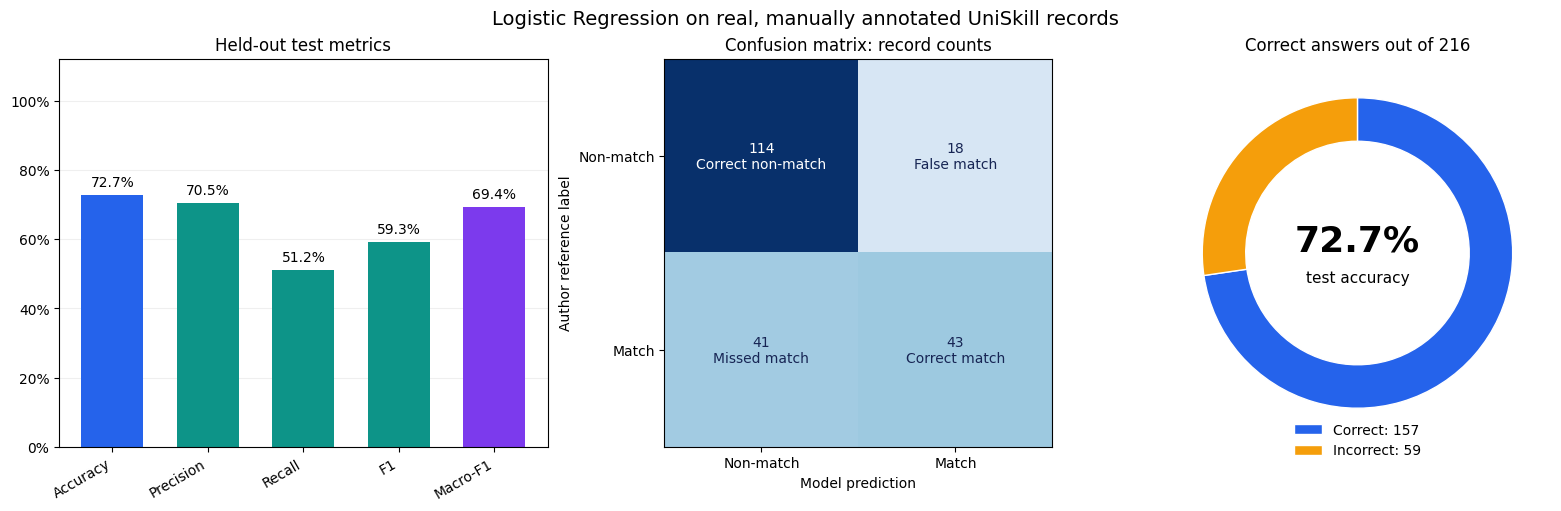

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

name = 'Logistic regression'
y_true = y[test_idx]
y_pred = predictions[name]
row = metrics.loc[metrics['method'].eq(name)].iloc[0]
correct = int(np.sum(y_true == y_pred))
incorrect = int(np.sum(y_true != y_pred))
accuracy = correct / len(y_true)
print(f'Test accuracy: {accuracy:.2%} ({correct} correct / {len(y_true)} records)')
print(f'Macro-F1: {row["macro_f1"]:.3f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
labels = ['Accuracy', 'Precision', 'Recall', 'F1', 'Macro-F1']
values = np.array([row['accuracy'], row['precision_match'], row['recall_match'], row['f1_match'], row['macro_f1']], dtype=float)
x = np.arange(len(labels))
bars = axes[0].bar(x, values, color=['#2563eb', '#0d9488', '#0d9488', '#0d9488', '#7c3aed'], width=0.65)
axes[0].set_xticks(x, labels, rotation=30, ha='right')
axes[0].set_ylim(0, 1.12)
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].set_title('Held-out test metrics')
axes[0].bar_label(bars, labels=[f'{v:.1%}' for v in values], padding=4)
axes[0].grid(axis='y', alpha=0.2)
axes[0].set_axisbelow(True)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
axes[1].imshow(cm, cmap='Blues', vmin=0, vmax=max(1, cm.max()))
axes[1].set_xticks([0, 1], ['Non-match', 'Match'])
axes[1].set_yticks([0, 1], ['Non-match', 'Match'])
axes[1].set_xlabel('Model prediction')
axes[1].set_ylabel('Author reference label')
axes[1].set_title('Confusion matrix: record counts')
cell_names = np.array([['Correct non-match', 'False match'], ['Missed match', 'Correct match']])
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f'{cm[i,j]}\n{cell_names[i,j]}', ha='center', va='center', fontsize=10, color='white' if cm[i,j] > cm.max()/2 else '#172554')

axes[2].pie([correct, incorrect], colors=['#2563eb', '#f59e0b'], startangle=90, counterclock=False, wedgeprops={'width':0.28, 'edgecolor':'white'})
axes[2].text(0, 0.08, f'{accuracy:.1%}', ha='center', va='center', fontsize=26, fontweight='bold')
axes[2].text(0, -0.16, 'test accuracy', ha='center', va='center', fontsize=11)
axes[2].legend([f'Correct: {correct}', f'Incorrect: {incorrect}'], loc='lower center', bbox_to_anchor=(0.5, -0.06), frameon=False)
axes[2].set_title(f'Correct answers out of {len(y_true)}')
fig.suptitle('Logistic Regression on real, manually annotated UniSkill records', fontsize=14)
fig.savefig(RESULT / 'model_results.png', dpi=180, bbox_inches='tight')
plt.show()

**How to read the results:** Accuracy is the proportion of all correct answers. Precision measures how many predicted matches are correct. Recall measures how many reference matches are found. Macro-F1 averages the F1 of match and non-match. The confusion matrix shows the errors directly. These results concern course–competency matching, not actual mentor assignment.